In [87]:
import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
from skimage import measure
import os
import pandas as pd
import scipy.io as sio
import logging

logging.getLogger().setLevel(logging.ERROR)
basepath =  r"V:\data\hpc_ctx_project\HP18\hp18_day17_20250421"
basename=os.path.basename(basepath)# Define the new folder path
#create working folder
new_folder_path = os.path.join(basepath, "complex_system")
brain_region="CA1"
animal="Rat"   #or Mouse
cell_type='all'
path_parts = basepath.split("\\")  # Split the path using backslash
animal_name = path_parts[-2]  # Second-to-last part is the animal name
day = path_parts[-1]  # Last part is the day
save_dir = r"D:\Documents\GitHub\R_Project\PPP\codebook\Criticality_analysis\complex_system\manifold"
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
# Create the folder if it doesn't exist
if not os.path.exists(new_folder_path):
    os.makedirs(new_folder_path)
    print(f"Folder created: {new_folder_path}")
else:
    print(f"Folder already exists: {new_folder_path}")
# load in spike data from hpc pyramidal cells
st, cm = loading.load_spikes(
    basepath, brainRegion=brain_region                          # putativeCellType="Pyr"
)
# load theta epochs
state_dict = loading.load_SleepState_states(basepath)
nrem_epochs = nel.EpochArray(
    state_dict["NREMstate"],
)
awake_epochs = nel.EpochArray(
    state_dict["WAKEstate"],
)
# theta_epochs = nel.EpochArray(
#     state_dict["THETA"],
# )
rem_epochs=nel.EpochArray(state_dict["REMstate"],)
try:
    # Try default loader
    epoch_df = loading.load_epoch(basepath)
except Exception as e:
    print(f"load_epoch failed with error: {e}")
    print("Falling back to manual .mat file load...")

    # Load the .mat file
    mat = sio.loadmat(os.path.join(basepath, "DayNight25.MergePoints.events.mat"), squeeze_me=True)

    # Extract the 'MergePoints' structure
    merge_points = mat['MergePoints']

    # Extract the timestamps array: shape (N, 2)
    timestamps = merge_points['timestamps']  # this is the field you're interested in
    # Unwrap the array inside
    timestamps = np.array(timestamps.tolist())

    # Now you should have shape (N, 2)
    epoch_df = pd.DataFrame(timestamps, columns=["startTime", "stopTime"])

sleep_epochs = nel.EpochArray(np.array([epoch_df.startTime, epoch_df.stopTime]).T)
E_spikes = st.time[(cm.putativeCellType == 'Pyramidal Cell')]
I_spikes= st.time[(cm.putativeCellType.str.contains("Interneuron"))]
spike_times=st.time
n_cell=len(spike_times)
print(f"number of cells: {n_cell}")
n_pyr=len(E_spikes)
print(f"number of pyramidal cells: {n_pyr}")
nrem_epochs.durations
print(f"NREM total duration: {nrem_epochs.durations[nrem_epochs.durations>60].sum():.2f} seconds")

Folder already exists: V:\data\hpc_ctx_project\HP18\hp18_day17_20250421\complex_system
number of cells: 152
number of pyramidal cells: 140
NREM total duration: 10701.00 seconds


In [88]:
epoch_df

,name,startTime,stopTime,environment,manipulation,notes,behavioralParadigm,stimuli,basepath
0,hp18_probe_250421_092212,0.0000,486.77115,cheeseboard,NaN,NaN,NaN,NaN,V:\data\hpc_ctx_project\HP18\hp18_day17_20250421
1,hp18_presleep_250421_093340,486.7712,8793.51035,sleep,NaN,NaN,NaN,NaN,V:\data\hpc_ctx_project\HP18\hp18_day17_20250421
2,hp18_cheeseboard1_250421_115426,8793.5104,10605.62555,cheeseboard,NaN,NaN,NaN,NaN,V:\data\hpc_ctx_project\HP18\hp18_day17_20250421
3,hp18_postsleep1_250421_122729,10605.6256,16031.56475,sleep,NaN,NaN,NaN,NaN,V:\data\hpc_ctx_project\HP18\hp18_day17_20250421
4,hp18_cheeseboard2_250421_140047,16031.5648,18024.95995,cheeseboard,NaN,NaN,NaN,NaN,V:\data\hpc_ctx_project\HP18\hp18_day17_20250421
5,hp18_postsleep2_250421_143905,18024.9600,26977.65115,sleep,pfc_silence,delta_closed_loop,NaN,NaN,V:\data\hpc_ctx_project\HP18\hp18_day17_20250421


In [89]:
import numpy as np

# ---- 1) flatten across units ----
# spike_times: length-49 container, each element is 1D array of spike times (seconds)
all_spikes = np.sort(np.concatenate([
    np.asarray(st, float).ravel()
    for st in spike_times
    if st is not None and len(st) > 0
]))

# (optional) drop NaNs/inf
all_spikes = all_spikes[np.isfinite(all_spikes)]
def mean_isi_in_epochs(all_spikes, epochs):
    """
    all_spikes: 1D sorted spike times (seconds)
    epochs: array-like of shape (n_epochs, 2) with [start, end] in seconds
            (if you have nel.EpochArray, pass epochs.data)
    Returns:
      per_epoch_mean_isi (seconds), overall_mean_isi (seconds), all_epoch_isis (1D)
    """
    all_spikes = np.asarray(all_spikes, float)
    epochs = np.asarray(epochs, float)

    per_epoch = []
    all_isis = []

    for start, end in epochs:
        i0 = np.searchsorted(all_spikes, start, side="left")
        i1 = np.searchsorted(all_spikes, end,   side="right")
        t = all_spikes[i0:i1]

        isi = np.diff(t)  # seconds, only within this epoch
        all_isis.append(isi)
        per_epoch.append(np.nan if isi.size == 0 else isi.mean())

    all_isis = np.concatenate(all_isis) if len(all_isis) else np.array([])
    overall = np.nan if all_isis.size == 0 else all_isis.mean()
    return np.asarray(per_epoch), overall, all_isis

# Example:
# NREM_epochs could be (n,2) array OR nel EpochArray -> use .data
per_epoch_mean_isi, overall_mean_isi, all_nrem_isis = mean_isi_in_epochs(
    all_spikes,
    nrem_epochs.data if hasattr(nrem_epochs, "data") else nrem_epochs
)

print("Overall mean ISI in NREM (s):", overall_mean_isi)
print("Overall mean ISI in NREM (ms):", overall_mean_isi * 1000)



Overall mean ISI in NREM (s): 0.004654162703150642
Overall mean ISI in NREM (ms): 4.654162703150642


In [90]:
import os, re, numpy as np, pandas as pd
import glob  # <-- add this
def _load_mat_any(mat_path):
    from scipy.io import loadmat
    try:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False,
            simplify_cells=True
        )
    except TypeError:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False
        )
    except NotImplementedError:
        import mat73
        return mat73.loadmat(mat_path)
def _to_1d_array(x):
    """
    Robustly coerce MATLAB-loaded field to a 1D numpy array.
    - Scalars -> 1-length array
    - Lists/tuples/ndarrays -> flattened 1D
    - None / missing -> empty array
    """
    if x is None:
        return np.array([], dtype=float)
    arr = np.asarray(x, dtype=object)  # start as object to avoid surprises
    if arr.ndim == 0:
        # scalar or unsized object
        return np.atleast_1d(arr).astype(float, copy=False)
    # flatten and try float cast (ignore non-numeric gracefully)
    try:
        return np.asarray(arr).ravel().astype(float, copy=False)
    except (ValueError, TypeError):
        # fallback: best-effort, convert elementwise
        return np.array([float(v) for v in np.ravel(arr)], dtype=float)

def _to_state_str(s):
    # MATLAB char arrays sometimes come in as numpy arrays
    try:
        if isinstance(s, (bytes, bytearray)):
            return s.decode('utf-8', 'ignore')
        if isinstance(s, str):
            return s
        # arrays or weird containers -> join characters
        arr = np.asarray(s)
        if arr.ndim == 0:
            return str(arr.item())
        # e.g., array of characters
        return ''.join(arr.tolist()) if arr.dtype.kind in ('U','S') else str(arr)
    except Exception:
        return str(s)

def load_d2_timeline_complete(basepath, region):
    """Complete version that loads ALL sleep-state data, including d2_err."""
    region = region.upper()
    search_dir = os.path.join(basepath, "complex_system")
    # pats = [f"*_{region}_D2_time_resolved_rippleablate.mat", f"*_{region}_D2_time_rippleablate.mat"]
    pats = [f"*_{region}_D2_time_resolved_error_bar_60ms.mat", f"*_{region}_D2_time_resolved_error_bar_60ms.mat"]
    files = []
    for pat in pats:
        files.extend(glob.glob(os.path.join(search_dir, pat)))
    if not files:
        raise FileNotFoundError(f"No *_{region}_D2_time*.mat under {search_dir}")

    mat_path = max(files, key=os.path.getmtime)
    print(f"Loading: {os.path.basename(mat_path)}")

    mat = _load_mat_any(mat_path)
    results = mat['results']
    params = mat.get('params', {})

    # Make results iterable no matter if it's a list, ndarray, or dict
    if isinstance(results, dict):
        iter_results = list(results.values())
    else:
        iter_results = list(results if isinstance(results, (list, tuple)) else np.atleast_1d(results))

    print(f"📊 Found {len(iter_results)} result items (sleep states)")
    print(f"📊 Parameters: {params}")

    # Try to infer animal/day from filename if available
    fname = os.path.basename(mat_path)
    animal_name = None
    day = None
    m_day = re.search(r'day(\d+)', fname, flags=re.I)
    if m_day:
        day = int(m_day.group(1))
    m_animal = re.match(r'([^_]+)_day\d+_', fname)
    if m_animal:
        animal_name = m_animal.group(1)

    all_centers, all_d2, all_d2err, all_states = [], [], [], []
    n_states_with_err = 0

    for i, result_item in enumerate(iter_results):
        # Access as dict-like regardless of MATLAB struct quirks
        state = _to_state_str(result_item.get('state', 'UNKNOWN')) if hasattr(result_item, 'get') else \
                _to_state_str(result_item['state']) if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) else 'UNKNOWN'

        centers_raw = result_item.get('center', []) if hasattr(result_item, 'get') else \
                      (result_item['center'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'center' in result_item else [])
        d2_raw = result_item.get('d2', []) if hasattr(result_item, 'get') else \
                 (result_item['d2'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2' in result_item else [])
        d2err_raw = result_item.get('d2_err', []) if hasattr(result_item, 'get') else \
                    (result_item['d2_err'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2_err' in result_item else [])

        centers  = _to_1d_array(centers_raw)
        d2_vals  = _to_1d_array(d2_raw)
        d2_err   = _to_1d_array(d2err_raw)

        # Presence flag (some states may not have d2_err)
        has_err = d2_err.size > 0 and np.any(np.isfinite(d2_err))
        n_states_with_err += int(has_err)

        # Harmonize lengths: truncate all to the common min
        sizes = [centers.size, d2_vals.size] + ([d2_err.size] if has_err else [])
        n_pts = min(sizes) if min(sizes) > 0 else 0
        print(f"   State {i}: {state} - requested points={centers.size}, actual used={n_pts}")

        if n_pts == 0:
            print("     ⚠️ Empty state - no data points")
            continue

        centers = centers[:n_pts]
        d2_vals = d2_vals[:n_pts]
        d2_err  = (d2_err[:n_pts] if has_err else np.full(n_pts, np.nan, dtype=float))

        # Ranges
        try:
            print(f"     Time range: {float(np.nanmin(centers))} to {float(np.nanmax(centers))}")
        except ValueError:
            print("     Time range: (all NaN)")

        try:
            print(f"     D2 range: {float(np.nanmin(d2_vals)):.4f} to {float(np.nanmax(d2_vals)):.4f}")
        except ValueError:
            print("     D2 range: (all NaN)")

        if np.any(np.isfinite(d2_err)):
            try:
                dmin, dmax = float(np.nanmin(d2_err)), float(np.nanmax(d2_err))
                print(f"     D2_ERR range: {dmin:.4f} to {dmax:.4f}")
            except ValueError:
                print("     D2_ERR range: (all NaN)")
        else:
            print("     D2_ERR: missing → filled with NaN")

        all_centers.append(centers)
        all_d2.append(d2_vals)
        all_d2err.append(d2_err)
        all_states.append(np.array([state]*n_pts, dtype=object))

    if len(all_centers) == 0:
        raise ValueError("No data found in any sleep state - all states are empty")

    # Concatenate
    all_centers = np.concatenate(all_centers)
    all_d2      = np.concatenate(all_d2)
    all_d2err   = np.concatenate(all_d2err)
    all_states  = np.concatenate(all_states)

    # DataFrame (include d2_err)
    df = pd.DataFrame({
        'center_s': all_centers.astype(float, copy=False),
        'd2':       all_d2.astype(float, copy=False),
        'd2_err':   all_d2err.astype(float, copy=False),
        'state':    all_states.astype(str)
    }).sort_values('center_s').reset_index(drop=True)

    print(f"\n✅ Complete timeline created:")
    print(f"📊 Total data points: {len(df)}")
    print(f"📊 Time range: {df['center_s'].min()} to {df['center_s'].max()}")
    print(f"📊 Duration: {(df['center_s'].max() - df['center_s'].min()):.1f} seconds")
    print(f"📊 State distribution:")
    print(df['state'].value_counts())

    # Empty-state tracker
    empty_states = []
    for ri in iter_results:
        st = _to_state_str(ri.get('state','UNKNOWN')) if hasattr(ri,'get') else \
             _to_state_str(ri['state']) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'state' in ri else 'UNKNOWN'
        csz = np.size(np.atleast_1d(ri.get('center', []))) if hasattr(ri,'get') else \
              np.size(np.atleast_1d(ri['center'])) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'center' in ri else 0
        if csz == 0:
            empty_states.append(st)

    meta = {
        "animal_name": animal_name,
        "day": day,
        "region": region,
        "path": mat_path,
        "params": params,
        "columns": list(df.columns),
        "shape": df.shape,
        "n_states": len(iter_results),
        "states_with_d2_err": n_states_with_err,
        "empty_states": empty_states
    }

    return df, meta



# Test the complete loading function
try:
    ca1_complete_df, ca1_complete_meta = load_d2_timeline_complete(basepath, "CA1")
    
    # pfc_complete_df, pfc_complete_meta = load_d2_timeline_complete(basepath, "PFC")

    
except Exception as e:
    print(f"❌ Failed: {e}")
    import traceback
    traceback.print_exc()

print("\n" + "="*60)

Loading: hp18_day17_20250421_CA1_D2_time_resolved_error_bar_60ms.mat
📊 Found 3 result items (sleep states)
📊 Parameters: {'window_size': 30, 'step_size': 2, 'guard_sec': 5, 'deltaT': 0.06, 'order': 20, 'quant': 0.1, 'brain_region': 'CA1', 'n_cells': 152, 'total_spikes': 5853410}
   State 0: NREM - requested points=4500, actual used=4500
     Time range: 1517.0 to 26833.0
     D2 range: 0.0561 to 0.2731
     D2_ERR range: 0.0150 to 0.0418
   State 1: REM - requested points=187, actual used=187
     Time range: 2974.0 to 24657.0
     D2 range: 0.0151 to 0.1419
     D2_ERR range: 0.0092 to 0.0314
   State 2: WAKE - requested points=6043, actual used=6043
     Time range: 21.0 to 26956.0
     D2 range: 0.0172 to 0.3663
     D2_ERR range: 0.0085 to 0.0554

✅ Complete timeline created:
📊 Total data points: 10730
📊 Time range: 21.0 to 26956.0
📊 Duration: 26935.0 seconds
📊 State distribution:
state
WAKE    6043
NREM    4500
REM      187
Name: count, dtype: int64



SWR and barrage

In [91]:
import numpy as np
import scipy.io as sio      
import scipy
# Load ripple events
ripple_events = loading.load_ripples_events(basepath=basepath)
ripple_epochs = nel.EpochArray(np.array([ripple_events.start, ripple_events.stop]).T)
ripple_peaks=ripple_events.peaks
    # Load barrage events
ripple_epochs=nrem_epochs&ripple_epochs
mask = (
    (epoch_df["environment"] == "sleep") &(epoch_df["manipulation"].isna())
    #  &
    # (epoch_df["name"].str.contains("postsleep", case=False, na=False))
)

sleep_no_manip_df = epoch_df.loc[mask, ["startTime", "stopTime"]]

# 2) make an EpochArray from these intervals
sleep_no_manip_epochs = nel.EpochArray(
    np.array(sleep_no_manip_df, dtype=float)
)

ripple_epochs=sleep_no_manip_epochs&ripple_epochs
try:
    # Load barrage events
    #brpath=r"W:\data\PPP\CA2\PPP7\day8"
    # Automatically detect the HSE filename based on basename
    barrage_events = loading.load_barrage_events(basepath=basepath)  
    # Create barrage epochs
    barrage_epochs = nel.EpochArray(np.array([barrage_events.start, barrage_events.stop]).T)
    # Find barrages in NREM epochs
    barrages_in_nrem = barrage_epochs & nrem_epochs
    mat_path = os.path.join(basepath, f'{basename}.HSEn2.events.mat')

    data = scipy.io.loadmat(mat_path, struct_as_record=False, squeeze_me=True)
    barrage = data['HSEn2']
    barrage_timestamps= barrage.timestamps 
    barrage_epochs=nrem_epochs&barrage_epochs

except Exception as e:
    # General exception for unexpected errors
    print(f"No barrage file: {e}")
    barrage_epochs=[]
    # Extract start times


No barrage file: 'DataFrame' object has no attribute 'start'


D:\Documents\GitHub\neuro_py\neuro_py\io\loading.py:1036: UserWarning: No barrage file found for V:\data\hpc_ctx_project\HP18\hp18_day17_20250421


In [92]:
import numpy as np

def mask_times_in_intervals(t, intervals):
    """
    t: (N,) times in seconds
    intervals: (M,2) [start, stop], assumed in seconds
    returns: (N,) boolean mask
    """
    t = np.asarray(t, float)
    iv = np.asarray(intervals, float)
    if iv.size == 0 or t.size == 0:
        return np.zeros_like(t, dtype=bool)

    # sort intervals by start
    order = np.argsort(iv[:, 0])
    iv = iv[order]
    starts = iv[:, 0]
    ends   = iv[:, 1]

    # find candidate interval for each t: last start <= t
    j = np.searchsorted(starts, t, side="right") - 1
    ok = (j >= 0) & (t < ends[np.clip(j, 0, len(ends)-1)]) & (t >= starts[np.clip(j, 0, len(starts)-1)])
    return ok

# ---- apply ----
intervals = sleep_no_manip_epochs.data   # Nx2
mask = mask_times_in_intervals(ca1_complete_df["center_s"].to_numpy(), intervals)

ca1_complete_df_sleep = ca1_complete_df.loc[mask].copy()
print("Before:", len(ca1_complete_df), "After:", len(ca1_complete_df_sleep))


Before: 10730 After: 5235



=== Session hp18_day17_20250421 ===
Using replay intervals from: D:\Documents\GitHub\Sleep_criticaltiy\data\replay\replay_nonreplay\hp18_day17_20250421_sig_replay.csv
Loaded 10270 significant replay intervals.
Total ripple events in ripple_epochs: 8243
Ripples IN replay:  3260
Ripples OUT replay: 3260


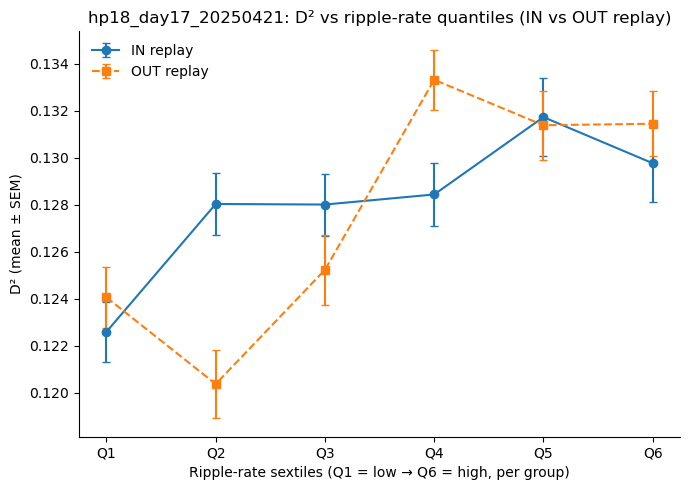

IN  counts per tile: [449, 508, 381, 355, 274, 357]
OUT counts per tile: [420, 367, 379, 501, 366, 291]


In [93]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import sem

SIG_DIR = r"D:\Documents\GitHub\Sleep_criticaltiy\data\replay\replay_nonreplay"   # your folder


def _force_sextiles(values, k=6):
    """
    Force k quantile tiles even if qcut collapses.
    Returns integer tiles in 1..k.
    """
    import pandas as pd
    import numpy as np

    x = pd.Series(values).astype(float)
    x = x.replace([np.inf, -np.inf], np.nan)

    # Attempt qcut first
    try:
        q = pd.qcut(x, q=k, labels=False, duplicates="drop")
        tiles = q.astype(float)
        n_unique = tiles.nunique()

        if n_unique == k:
            return tiles.astype(int) + 1  # perfect case

    except Exception:
        pass

    # Fallback: rank-based forced quantiles
    # ------------------------------------
    ranks = x.rank(method="first")      # 1..N
    N = ranks.max()

    if N == 0 or not np.isfinite(N):
        return pd.Series([np.nan] * len(x), index=x.index)

    tiles = np.ceil(ranks / (N / k)).astype(int)
    tiles[tiles < 1] = 1
    tiles[tiles > k] = k

    return pd.Series(tiles, index=x.index)

# -------------------------------------------------------------------
# Helper: convert ripple_epochs to clean (N,2) float array
# -------------------------------------------------------------------
def _to_intervals(obj):
    import numpy as _np

    if obj is None:
        return _np.empty((0,2), float)

    if isinstance(obj, _np.ndarray):
        arr = obj
    elif hasattr(obj, "data"):
        arr = _np.asarray(obj.data)
    elif isinstance(obj, dict) and "data" in obj:
        arr = _np.asarray(obj["data"])
    else:
        arr = _np.asarray(obj)

    arr = arr.astype(float)
    mask = _np.isfinite(arr).all(1) & (arr[:,0] < arr[:,1])
    return arr[mask]


# -------------------------------------------------------------------
# Overlap helpers
# -------------------------------------------------------------------
def overlaps_any(interval, others):
    a0, a1 = interval
    if others.size == 0:
        return False
    return np.any((a0 < others[:,1]) & (a1 > others[:,0]))


def count_overlaps_in_window(intervals, w0, w1):
    if intervals.size == 0:
        return 0
    return int(np.sum((intervals[:,0] < w1) & (intervals[:,1] > w0)))

# ----------------------------------------------------------------
# Forced quantile-tiling summary
# ----------------------------------------------------------------
def _forced_sextile_summary(df, rate_column, y_column, k=6):
    import numpy as np
    import pandas as pd

    sub = df[[rate_column, y_column]].replace([np.inf, -np.inf], np.nan).dropna().copy()
    out_index = np.arange(1, k + 1)

    if sub.empty:
        return pd.DataFrame({"mean": np.nan, "sem": np.nan, "count": 0}, index=out_index)

    sub["_tile"] = _force_sextiles(sub[rate_column].to_numpy(float), k=k).to_numpy(int)

    g = sub.groupby("_tile")[y_column]
    means  = g.mean()
    sems   = g.sem()
    counts = g.size()

    out = pd.DataFrame(index=out_index, columns=["mean", "sem", "count"], dtype=float)
    out["mean"]  = means.reindex(out_index).values
    out["sem"]   = sems.reindex(out_index).values
    out["count"] = counts.reindex(out_index).fillna(0).astype(int).values
    return out

def _forced_equalwidth_summary(df, rate_column, y_column, k=6):
    import numpy as np
    import pandas as pd

    sub = df[[rate_column, y_column]].dropna().copy()
    out_index = np.arange(1, k + 1)

    # empty
    if sub.empty:
        return pd.DataFrame({"mean": np.nan, "sem": np.nan, "count": 0}, index=out_index)

    x = pd.to_numeric(sub[rate_column], errors="coerce")
    y = pd.to_numeric(sub[y_column], errors="coerce")
    sub = sub.loc[np.isfinite(x) & np.isfinite(y)].copy()
    sub[rate_column] = x.loc[sub.index]
    sub[y_column] = y.loc[sub.index]

    if sub.empty:
        return pd.DataFrame({"mean": np.nan, "sem": np.nan, "count": 0}, index=out_index)

    xmin = sub[rate_column].min()
    xmax = sub[rate_column].max()

    # if constant, can't bin by width
    if not np.isfinite(xmin) or not np.isfinite(xmax) or (xmax <= xmin):
        return pd.DataFrame({"mean": np.nan, "sem": np.nan, "count": len(sub)}, index=out_index)

    # equal-width edges (k bins)
    edges = np.linspace(xmin, xmax, k + 1)

    # make sure the max value falls into the last bin
    edges[-1] = np.nextafter(edges[-1], np.inf)

    tiles = pd.cut(
        sub[rate_column],
        bins=edges,
        labels=False,
        include_lowest=True,
        right=False
    ) + 1  # -> 1..k

    sub["_tile"] = tiles.astype(int)

    g = sub.groupby("_tile")[y_column]
    means = g.mean()
    sems = g.sem()
    counts = g.size()

    out = pd.DataFrame(index=out_index, columns=["mean", "sem", "count"], dtype=float)
    out["mean"]  = means.reindex(out_index).values
    out["sem"]   = sems.reindex(out_index).values
    out["count"] = counts.reindex(out_index).fillna(0).astype(int).values
    return out

def unique_intervals(replay_intervals, decimals=6, sort=True):
    # accept nelpy EpochArray or raw Nx2
    iv = replay_intervals.data if hasattr(replay_intervals, "data") else replay_intervals
    iv = np.asarray(iv, dtype=float)

    if iv.size == 0:
        return iv.reshape(0, 2)

    # deal with float jitter (e.g., 0.30000000004)
    ivr = np.round(iv, decimals=decimals)

    # unique rows
    u = np.unique(ivr, axis=0)

    if sort:
        u = u[np.lexsort((u[:, 1], u[:, 0]))]  # sort by start then end
    return u
def count_overlaps_many(intervals, w0, w1):
    """
    Count how many intervals overlap each window [w0[i], w1[i]].
    intervals: (N,2) array
    w0, w1: arrays length M
    returns: counts array length M (int)
    """
    intervals = np.asarray(intervals, float)
    if intervals.size == 0:
        return np.zeros_like(w0, dtype=int)

    starts = np.sort(intervals[:, 0])
    ends   = np.sort(intervals[:, 1])

    # overlap condition: start < w1 and end > w0
    # count = #{start < w1} - #{end <= w0}
    return (np.searchsorted(starts, w1, side="left")
            - np.searchsorted(ends,   w0, side="right")).astype(int)

# -------------------------------------------------------------------
# MAIN FUNCTION – NOW USES 6 QUANTILE TILES PER GROUP
# -------------------------------------------------------------------
def run_replay_d2_for_session(
    basepath,
    ripple_epochs,
    centers,
    d2_values,
    d2_errors,
    d2_window_size,
    n_bins=6
):
    """
    Reads replay intervals from:
        W:/Hongyu/ryan/sig_replay_windows/{session}_sig_replay.csv

    Computes:
        - ripples IN replay
        - ripples OUT replay
        - ripple_rate_in / ripple_rate_out in each D² window
        - 6 *quantile* tiles of ripple rate vs D² for IN and OUT separately
    """
    session_id = os.path.basename(basepath)

    replay_csv = os.path.join(SIG_DIR, f"{session_id}_sig_replay.csv")
    if not os.path.exists(replay_csv):
        print(f"[WARN] No replay CSV found for {session_id}: {replay_csv}")
        return

    print(f"\n=== Session {session_id} ===")
    print(f"Using replay intervals from: {replay_csv}")

    # ----------------------------------------------------------------
    # LOAD SIGNIFICANT REPLAY WINDOWS
    # ----------------------------------------------------------------
    df_replay = pd.read_csv(replay_csv)

    if df_replay.empty:
        print(f"[INFO] {session_id}: no significant replay rows, skipping.")
        return

    replay_intervals = df_replay[["ripple_start", "ripple_stop"]].to_numpy(float)
    print(f"Loaded {len(replay_intervals)} significant replay intervals.")


    # ----------------------------------------------------------------
    # Ripple epochs → intervals
    # ----------------------------------------------------------------
    ripples = _to_intervals(ripple_epochs)
    print(f"Total ripple events in ripple_epochs: {len(ripples)}")
    u_replay = unique_intervals(replay_intervals, decimals=6)
    
    # IN / OUT classification
    in_mask = np.array([overlaps_any(r, u_replay) for r in ripples], dtype=bool)
    ripples_in  = ripples[in_mask]
    ripples_out = ripples[~in_mask]
    n_in = len(ripples_in)
    n_out = len(ripples_out)

    if n_out > n_in:
        # Randomly subsample OUT to match IN count
        idx = np.random.choice(n_out, size=n_in, replace=False)
        ripples_out_matched = ripples_out[idx]
    else:
        ripples_out_matched = ripples_out
    print(f"Ripples IN replay:  {len(ripples_in)}")
    print(f"Ripples OUT replay: {len(ripples_out_matched)}")

    # ----------------------------------------------------------------
    # Compute ripple rates per D² window
    # ----------------------------------------------------------------
    centers = np.asarray(centers, float)
    d2_vals = np.asarray(d2_values, float)
    d2_errs = np.zeros_like(d2_vals) if d2_errors is None else np.asarray(d2_errors, float)

    data_rows = []

    for c, d2 in zip(centers, d2_vals):
        if not np.isfinite(d2):
            continue

        w0 = c - d2_window_size/2
        w1 = c + d2_window_size/2

        rate_in  = count_overlaps_in_window(ripples_in,  w0, w1) / d2_window_size
        rate_out = count_overlaps_in_window(ripples_out_matched, w0, w1) / d2_window_size

        data_rows.append([c, d2, rate_in, rate_out, d2_errs])

    df_win = pd.DataFrame(
    data_rows,
    columns=["center", "d2", "rate_in", "rate_out", "d2_err"]
    )

    df_win["animal_name"] = animal_name
    df_win["day"] = day

    df_win = df_win.dropna()

    # ----------------------------------------------------------------
    # Quantile-tiling helper: forced 6 tiles per group (padded)
    # ----------------------------------------------------------------

    # summ_in  = _quantile_summary(df_win, "rate_in",  "d2", n_bins)
    # summ_out = _quantile_summary(df_win, "rate_out", "d2", n_bins)
    summ_in  = _forced_sextile_summary(df_win, "rate_in",  "d2", k=n_bins)
    summ_out = _forced_sextile_summary(df_win, "rate_out", "d2", k=n_bins)

    # ----------------------------------------------------------------
    # Plot
    # ----------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(7,5))

    x = np.arange(1, n_bins+1)
    labels = [f"Q{i}" for i in x]

    ax.errorbar(x, summ_in["mean"],  yerr=summ_in["sem"],
                fmt="o-", capsize=3, label="IN replay")
    ax.errorbar(x, summ_out["mean"], yerr=summ_out["sem"],
                fmt="s--", capsize=3, label="OUT replay")

    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_xlabel("Ripple-rate sextiles (Q1 = low → Q6 = high, per group)")
    ax.set_ylabel("D² (mean ± SEM)")
    ax.set_title(f"{session_id}: D² vs ripple-rate quantiles (IN vs OUT replay)")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False)

    plt.tight_layout()
    plt.show()

    print("IN  counts per tile:",  summ_in["count"].astype(int).tolist())
    print("OUT counts per tile:",  summ_out["count"].astype(int).tolist())
    return df_win
# --- filter to NREM only ---
df_nrem =ca1_complete_df_sleep[ca1_complete_df_sleep["state"] == "NREM"].copy()

centers = df_nrem["center_s"].values
d2_values = df_nrem["d2"].values
d2_errors = df_nrem["d2_err"].values if "d2_err" in df_nrem.columns else None

analysis_df=run_replay_d2_for_session(
    basepath       = basepath,
    ripple_epochs  = ripple_epochs,
    centers        = centers,
    d2_values      = d2_values,
    d2_errors      = d2_errors,
    d2_window_size =30,
)



=== Session hp18_day17_20250421 ===
Using replay intervals from: D:\Documents\GitHub\Sleep_criticaltiy\data\replay\replay_nonreplay\hp18_day17_20250421_sig_replay.csv
Total ripple events in ripple_epochs: 8243
Ripples IN replay:  3260
Ripples OUT replay: 4983


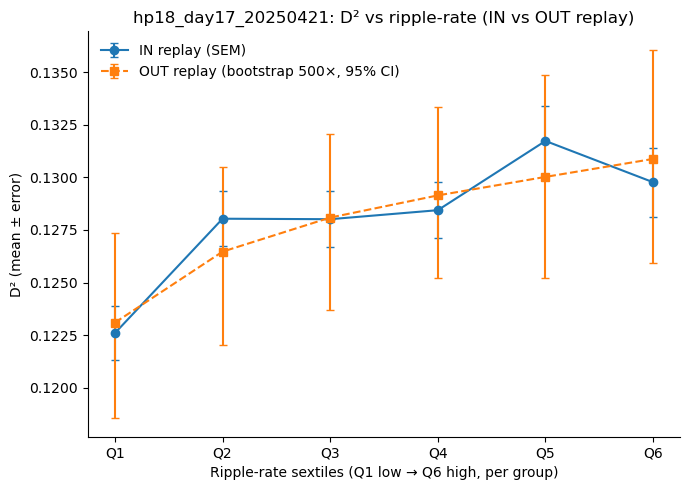

IN counts per tile: [449, 508, 381, 355, 274, 357]
OUT median counts per tile (bootstrap): [432, 427, 343, 415, 343, 351]


In [94]:
def _forced_sextile_summary(df, rate_column, y_column, k=6):
    import numpy as np
    import pandas as pd

    sub = df[[rate_column, y_column]].replace([np.inf, -np.inf], np.nan).dropna().copy()
    out_index = np.arange(1, k + 1)

    if sub.empty:
        return pd.DataFrame({"mean": np.nan, "sem": np.nan, "count": 0}, index=out_index)

    sub["_tile"] = _force_sextiles(sub[rate_column].to_numpy(float), k=k).to_numpy(int)

    g = sub.groupby("_tile")[y_column]
    means  = g.mean()
    sems   = g.sem()
    counts = g.size()

    out = pd.DataFrame(index=out_index, columns=["mean", "sem", "count"], dtype=float)
    out["mean"]  = means.reindex(out_index).values
    out["sem"]   = sems.reindex(out_index).values
    out["count"] = counts.reindex(out_index).fillna(0).astype(int).values
    return out
def _forced_equalwidth_summary(df, rate_column, y_column, k=6):
    import numpy as np
    import pandas as pd

    sub = df[[rate_column, y_column]].replace([np.inf, -np.inf], np.nan).dropna().copy()
    out_index = np.arange(1, k + 1)

    if sub.empty:
        return pd.DataFrame({"mean": np.nan, "sem": np.nan, "count": 0}, index=out_index)

    x = sub[rate_column].to_numpy(float)
    lo = np.nanmin(x); hi = np.nanmax(x)
    if (not np.isfinite(lo)) or (not np.isfinite(hi)) or (hi <= lo):
        return pd.DataFrame({"mean": np.nan, "sem": np.nan, "count": len(sub)}, index=out_index)

    # k equal-width bins over [lo, hi]
    edges = np.linspace(lo, hi, k + 1)
    edges[-1] = np.nextafter(edges[-1], np.inf)  # include max in last bin

    # tiles in 1..k
    sub["_tile"] = np.digitize(x, edges[1:-1], right=False) + 1

    g = sub.groupby("_tile")[y_column]
    means  = g.mean()
    sems   = g.sem()
    counts = g.size()

    out = pd.DataFrame(index=out_index, columns=["mean", "sem", "count"], dtype=float)
    out["mean"]  = means.reindex(out_index).values
    out["sem"]   = sems.reindex(out_index).values
    out["count"] = counts.reindex(out_index).fillna(0).astype(int).values
    return out

def run_replay_d2_for_session(
    basepath,
    ripple_epochs,
    centers,
    d2_values,
    d2_errors,
    d2_window_size,
    n_bins=6,
    tile_mode="equal",
    n_boot=500,
    replace=True,   # True = classic bootstrap; False = Monte-Carlo matching (no replacement)
    seed=0,
):
    session_id = os.path.basename(basepath)

    # infer animal/day from folder structure: .../<animal>/<day>
    animal_name = os.path.basename(os.path.dirname(basepath))
    day         = os.path.basename(basepath)

    replay_csv = os.path.join(SIG_DIR, f"{session_id}_sig_replay.csv")
    if not os.path.exists(replay_csv):
        print(f"[WARN] No replay CSV found for {session_id}: {replay_csv}")
        return None

    print(f"\n=== Session {session_id} ===")
    print(f"Using replay intervals from: {replay_csv}")

    df_replay = pd.read_csv(replay_csv)
    if df_replay.empty:
        print(f"[INFO] {session_id}: no significant replay rows, skipping.")
        return None

    replay_intervals = df_replay[["ripple_start", "ripple_stop"]].to_numpy(float)
    u_replay = unique_intervals(replay_intervals, decimals=6)

    # Ripple epochs → intervals
    ripples = _to_intervals(ripple_epochs)
    print(f"Total ripple events in ripple_epochs: {len(ripples)}")

    # IN / OUT classification
    in_mask = np.array([overlaps_any(r, u_replay) for r in ripples], dtype=bool)
    ripples_in  = ripples[in_mask]
    ripples_out = ripples[~in_mask]
    n_in  = len(ripples_in)
    n_out = len(ripples_out)

    print(f"Ripples IN replay:  {n_in}")
    print(f"Ripples OUT replay: {n_out}")

    # ---- build windows once; keep only finite rows ----
    centers = np.asarray(centers, float)
    d2_vals = np.asarray(d2_values, float)
    d2_errs = np.zeros_like(d2_vals) if d2_errors is None else np.asarray(d2_errors, float)

    ok = np.isfinite(centers) & np.isfinite(d2_vals)
    centers = centers[ok]
    d2_vals = d2_vals[ok]
    d2_errs = d2_errs[ok]

    w0 = centers - d2_window_size / 2.0
    w1 = centers + d2_window_size / 2.0

    # ---- IN rate per window (no bootstrap) ----
    counts_in = count_overlaps_many(ripples_in, w0, w1)
    rate_in   = counts_in / float(d2_window_size)

    # ---- OUT bootstrap: store (a) per-window mean/sd, (b) per-bin D2 mean distribution ----
    rng = np.random.default_rng(seed)

    # per-window online mean/var (Welford)
    M = len(centers)
    mean_out = np.zeros(M, float)
    M2_out   = np.zeros(M, float)
    n_seen   = 0

    boot_bin_means  = np.full((n_boot, n_bins), np.nan, float)
    boot_bin_counts = np.zeros((n_boot, n_bins), int)

    if n_in == 0 or n_out == 0:
        print("[WARN] Not enough IN/OUT ripples to bootstrap.")
        df_win = pd.DataFrame({
            "animal_name": animal_name,
            "day": day,
            "center": centers,
            "d2": d2_vals,
            "d2_err": d2_errs,
            "rate_in": rate_in,
            "rate_out_mean": np.nan,
            "rate_out_sd": np.nan,
        })
        return df_win

    for b in range(n_boot):
        # sample OUT ripples to match IN count
        if n_out >= n_in:
            idx = rng.choice(n_out, size=n_in, replace=replace)
        else:
            # cannot draw n_in distinct if OUT smaller
            idx = rng.choice(n_out, size=n_in, replace=True)

        ripples_out_b = ripples_out[idx]
        counts_out_b  = count_overlaps_many(ripples_out_b, w0, w1)
        rate_out_b    = counts_out_b / float(d2_window_size)

        # online update per-window mean/sd
        n_seen += 1
        delta  = rate_out_b - mean_out
        mean_out += delta / n_seen
        M2_out   += delta * (rate_out_b - mean_out)

        # bin summary for this bootstrap (forced sextiles)
        df_out_b = pd.DataFrame({"rate_out": rate_out_b, "d2": d2_vals})
        if tile_mode == "equal":
            summ_out_b = _forced_equalwidth_summary(df_out_b, "rate_out", "d2", k=n_bins)
        else:
            summ_out_b = _forced_sextile_summary(df_out_b, "rate_out", "d2", k=n_bins)

        boot_bin_means[b, :]  = summ_out_b["mean"].to_numpy()
        boot_bin_counts[b, :] = summ_out_b["count"].to_numpy(dtype=int)


        boot_bin_means[b, :]  = summ_out_b["mean"].to_numpy()
        boot_bin_counts[b, :] = summ_out_b["count"].to_numpy(dtype=int)

    sd_out = np.sqrt(M2_out / max(n_seen - 1, 1))

    # ---- df_win: store per-window OUT bootstrap mean/sd ----
    df_win = pd.DataFrame({
        "animal_name": animal_name,
        "day": day,
        "center": centers,
        "d2": d2_vals,
        "d2_err": d2_errs,
        "rate_in": rate_in,
        "rate_out_mean": mean_out,
        "rate_out_sd": sd_out,
    })
    # keep a single "rate_out" for downstream code
    df_win["rate_out"] = df_win["rate_out_mean"]

    # ---- sextile summaries for plotting ----
    if tile_mode == "equal":
        summ_in = _forced_equalwidth_summary(df_win, "rate_in", "d2", k=n_bins)
    else:
        summ_in = _forced_sextile_summary(df_win, "rate_in", "d2", k=n_bins)


    out_mean = np.nanmean(boot_bin_means, axis=0)
    out_lo   = np.nanpercentile(boot_bin_means, 2.5, axis=0)
    out_hi   = np.nanpercentile(boot_bin_means, 97.5, axis=0)
    out_yerr = np.vstack([out_mean - out_lo, out_hi - out_mean])  # asymmetric CI

    # ---- Plot ----
    fig, ax = plt.subplots(figsize=(7, 5))
    x = np.arange(1, n_bins + 1)
    labels = [f"Q{i}" for i in x]

    ax.errorbar(x, summ_in["mean"], yerr=summ_in["sem"],
                fmt="o-", capsize=3, label="IN replay (SEM)")
    ax.errorbar(x, out_mean, yerr=out_yerr,
                fmt="s--", capsize=3, label=f"OUT replay (bootstrap {n_boot}×, 95% CI)")

    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_xlabel("Ripple-rate sextiles (Q1 low → Q6 high, per group)")
    ax.set_ylabel("D² (mean ± error)")
    ax.set_title(f"{session_id}: D² vs ripple-rate (IN vs OUT replay)")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()
    df_tile = pd.DataFrame({
        "animal_name": animal_name,
        "day": day,
        "tile_num": np.arange(1, n_bins+1),

        "in_d2_mean": summ_in["mean"].to_numpy(),
        "in_d2_sem":  summ_in["sem"].to_numpy(),

        "out_d2_mean": out_mean,
        "out_d2_lo":   out_lo,
        "out_d2_hi":   out_hi,
    })
    print("IN counts per tile:", summ_in["count"].astype(int).tolist())
    print("OUT median counts per tile (bootstrap):",
          np.median(boot_bin_counts, axis=0).astype(int).tolist())

    return df_win, df_tile
analysis_df, df_tile = run_replay_d2_for_session(
    basepath       = basepath,
    ripple_epochs  = ripple_epochs,
    centers        = centers,
    d2_values      = d2_values,
    d2_errors      = d2_errors,
    d2_window_size = 30,
    n_bins         = 6,
    n_boot         = 500,
    tile_mode="quantile",
    replace        = True,
    seed           = 0,
)


In [95]:
def _forced_equalwidth_summary(df, rate_column, y_column, k=6):
    import numpy as np
    import pandas as pd

    sub = df[[rate_column, y_column]].replace([np.inf, -np.inf], np.nan).dropna().copy()
    out_index = np.arange(1, k + 1)

    if sub.empty:
        return pd.DataFrame({"mean": np.nan, "sem": np.nan, "count": 0}, index=out_index)

    x = sub[rate_column].to_numpy(float)
    lo = np.nanmin(x); hi = np.nanmax(x)
    if (not np.isfinite(lo)) or (not np.isfinite(hi)) or (hi <= lo):
        return pd.DataFrame({"mean": np.nan, "sem": np.nan, "count": len(sub)}, index=out_index)

    # k equal-width bins over [lo, hi]
    edges = np.linspace(lo, hi, k + 1)
    edges[-1] = np.nextafter(edges[-1], np.inf)  # include max in last bin

    # tiles in 1..k
    sub["_tile"] = np.digitize(x, edges[1:-1], right=False) + 1

    g = sub.groupby("_tile")[y_column]
    means  = g.mean()
    sems   = g.sem()
    counts = g.size()

    out = pd.DataFrame(index=out_index, columns=["mean", "sem", "count"], dtype=float)
    out["mean"]  = means.reindex(out_index).values
    out["sem"]   = sems.reindex(out_index).values
    out["count"] = counts.reindex(out_index).fillna(0).astype(int).values
    return out


In [96]:

from pathlib import Path
import pandas as pd

# Inputs you already have:
# ca1_complete_df : pandas DataFrame
# animal_name     : str
# day             : int | str
# brain_region    : str

out_dir = Path(r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats\replay_nonreplay")
out_dir.mkdir(parents=True, exist_ok=True)

fname = f"{animal_name}_{day}_{brain_region}.pkl"
save_path = out_dir / fname
fname=f"{animal_name}_{day}_{brain_region}_tile.pkl"
tile_save_path = out_dir / fname
analysis_df.to_pickle(save_path)
df_tile.to_pickle(tile_save_path)
print(f"Saved to: {save_path}")
print(f"Saved to: {tile_save_path}")
# Later, to load:
# df = pd.read_pickle(save_path)


Saved to: D:\Documents\GitHub\Sleep_criticaltiy\data\rats\replay_nonreplay\HP18_hp18_day17_20250421_CA1.pkl
Saved to: D:\Documents\GitHub\Sleep_criticaltiy\data\rats\replay_nonreplay\HP18_hp18_day17_20250421_CA1_tile.pkl


In [97]:
# import os
# import re
# import pandas as pd
# import numpy as np
# from pathlib import PureWindowsPath

# # ---------------- paths ----------------
# csv_path = r"W:\Hongyu\ryan\replay_2d_results.csv"
# out_dir  = r"D:\Documents\GitHub\Sleep_criticaltiy\data\replay\significant_replay_by_basepath"
# os.makedirs(out_dir, exist_ok=True)

# df = pd.read_csv(csv_path, low_memory=False)

# # ---------------- column helpers ----------------
# def pick_col(df, candidates, required=True):
#     for c in candidates:
#         if c in df.columns:
#             return c
#     if required:
#         raise KeyError(f"None of these columns found: {candidates}\nAvailable: {df.columns.tolist()}")
#     return None

# base_col  = pick_col(df, ["basepath"])

# start_col = pick_col(df, ["ripple_start"])
# stop_col  = pick_col(df, ["ripple_stop"])
# epoch_col = pick_col(df, ["epoch", "epoch_name", "trajectory_epoch", "template_epoch"])
# dir_col   = pick_col(df, ["direction"], required=False)

# # --- significance columns ---
# p_spatial = pick_col(df, ["score_pval_spatial_posterior"])
# jump_col  = pick_col(df, ["jump"])

# # ---------------- filter: significant replay ----------------
# # significant_replay = (score_pval_spatial_posterior < 0.05) & (jump < 12)

# p_sp = pd.to_numeric(df[p_spatial], errors="coerce")
# jump = pd.to_numeric(df[jump_col], errors="coerce")

# sig_mask = (p_sp < 0.05) & (jump < 12)

# sig = df.loc[sig_mask, [base_col, start_col, stop_col, epoch_col]].copy()
# if dir_col:
#     sig = df.loc[sig_mask, [base_col, start_col, stop_col, epoch_col, dir_col]].copy()

# # optional: clean strings
# sig[base_col]  = sig[base_col].astype(str).str.strip()
# sig[epoch_col] = sig[epoch_col].astype(str).str.strip()
# if dir_col:
#     sig[dir_col]   = sig[dir_col].astype(str).str.strip()

# # ---------------- save one CSV per basepath ----------------
# def safe_name(s):
#     s = str(s)
#     s = re.sub(r'[<>:"/\|?*]', "_", s)
#     return s

# n_written = 0
# for bp, sub in sig.groupby(base_col, dropna=False):
#     folder = PureWindowsPath(bp).name if bp and bp != "nan" else "UNKNOWN_BASEPATH"
#     fname = safe_name(folder) + "_sig_replay.csv"
#     out_path = os.path.join(out_dir, fname)

#     cols_out = [start_col, stop_col, epoch_col]
#     if dir_col and dir_col in sub.columns:
#         cols_out.append(dir_col)
    
#     sub_out = sub[cols_out].reset_index(drop=True)
#     sub_out[start_col] = pd.to_numeric(sub_out[start_col], errors="coerce")
#     sub_out = sub_out.sort_values(start_col, kind="mergesort")

#     sub_out.to_csv(out_path, index=False)
#     n_written += 1
#     print(f"[saved] {out_path}  (n={len(sub_out)})")

# print(f"Total files written: {n_written}")

In [98]:
# import os
# import re
# import pandas as pd
# import numpy as np
# from pathlib import PureWindowsPath

# # ---------------- paths ----------------
# csv_path = r"W:\Hongyu\ryan\replay_2d_results.csv"
# out_dir  = r"D:\Documents\GitHub\Sleep_criticaltiy\data\replay\significant_replay_by_basepath"
# os.makedirs(out_dir, exist_ok=True)

# df = pd.read_csv(csv_path, low_memory=False)

# # ---------------- column helpers ----------------
# def pick_col(df, candidates, required=True):
#     for c in candidates:
#         if c in df.columns:
#             return c
#     if required:
#         raise KeyError(f"None of these columns found: {candidates}\nAvailable: {df.columns.tolist()}")
#     return None

# base_col  = pick_col(df, ["basepath"])

# start_col = pick_col(df, ["ripple_start", "ripple_start"])
# stop_col  = pick_col(df, ["ripple_stop", "ripple_stop"])
# epoch_col = pick_col(df, ["epoch", "epoch_name", "trajectory_epoch", "template_epoch"])
# dir_col   = pick_col(df, ["direction"])

# # --- p-values (the 3 you mentioned) ---
# p_time  = pick_col(df, ["score_pval_time_swap"])
# p_cycle = pick_col(df, ["score_pval_col_cycle"])
# p_r2    = pick_col(df, ["decoding_r2_pval"])

# # ---------------- filter: significant replay ----------------
# alpha = 0.05

# pt  = pd.to_numeric(df[p_time],  errors="coerce")
# pc  = pd.to_numeric(df[p_cycle], errors="coerce")
# pr2 = pd.to_numeric(df[p_r2],    errors="coerce")

# sig_mask = (pt < alpha)

# sig = df.loc[sig_mask, [base_col, start_col, stop_col, epoch_col, dir_col]].copy()

# # optional: clean strings
# sig[base_col]  = sig[base_col].astype(str).str.strip()
# sig[epoch_col] = sig[epoch_col].astype(str).str.strip()
# sig[dir_col]   = sig[dir_col].astype(str).str.strip()

# # ---------------- save one CSV per basepath ----------------
# def safe_name(s):
#     s = str(s)
#     s = re.sub(r'[<>:"/\\|?*]', "_", s)
#     return s

# n_written = 0
# for bp, sub in sig.groupby(base_col, dropna=False):
#     folder = PureWindowsPath(bp).name if bp and bp != "nan" else "UNKNOWN_BASEPATH"
#     fname = safe_name(folder) + "_sig_replay.csv"
#     out_path = os.path.join(out_dir, fname)

#     sub_out = sub[[start_col, stop_col, epoch_col, dir_col]].reset_index(drop=True)
#     sub_out[start_col] = pd.to_numeric(sub_out[start_col], errors="coerce")
#     sub_out = sub_out.sort_values(start_col, kind="mergesort")

#     sub_out.to_csv(out_path, index=False)
#     n_written += 1
#     print(f"[saved] {out_path}  (n={len(sub_out)})")

# print(f"\nDone. Wrote {n_written} files to:\n{out_dir}")
